In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.metrics import confusion_matrix

In [41]:
# 2. Load MNIST data
train_data = pd.read_csv("fashion-mnist_train.csv")
test_data = pd.read_csv("fashion-mnist_test.csv")

print("Training Data:", train_data.shape)
print("Testing Data:", test_data.shape)

Training Data: (60000, 785)
Testing Data: (10000, 785)


In [42]:
# 3. Separate features and labels
X_train = train_data.drop("label", axis=1).values
y_train = train_data["label"].values

X_test = test_data.drop("label", axis=1).values
y_test = test_data["label"].values

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)


Training images: (60000, 784)
Training labels: (60000,)
Testing images: (10000, 784)
Testing labels: (10000,)


In [43]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

In [44]:
# Normalize pixel values between 0 and 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Reshape images into 28x28 with 1 color channel
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (60000, 28, 28, 1)
Testing Shape: (10000, 28, 28, 1)


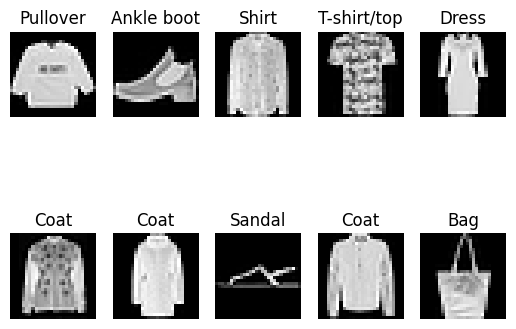

In [45]:
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(X_train[i],cmap ="gray")
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.show()

In [46]:
# Build CNN model
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    MaxPooling2D((2,2)),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.3),

    Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [47]:
# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [48]:
# Display model summary
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [49]:
# Train the model
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 55s 127ms/step - accuracy: 0.7702 - loss: 0.6270 - val_accuracy: 0.8558 - val_loss: 0.4044
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 75s 110ms/step - accuracy: 0.8556 - loss: 0.3987 - val_accuracy: 0.8702 - val_loss: 0.3566
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 71s 169ms/step - accuracy: 0.8737 - loss: 0.3471 - val_accuracy: 0.8830 - val_loss: 0.3143
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 59s 114ms/step - accuracy: 0.8841 - loss: 0.3164 - val_accuracy: 0.8943 - val_loss: 0.2942
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 48s 115ms/step - accuracy: 0.8945 - loss: 0.2896 - val_accuracy: 0.8973 - val_loss: 0.2915
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 79s 108ms/step - accuracy: 0.8994 - loss: 0.2763 - val_accuracy: 0.9018 - val_loss: 0.2852
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 84s 112ms/step - accuracy: 0.9070 - loss: 0.2565 - val_accuracy: 0.9082 - val_loss: 0.2592
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 81s 111ms/step - accuracy: 0.9098 - loss: 0

In [50]:
# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9128 - loss: 0.2342
Test Loss: 0.23418627679347992
Test Accuracy: 0.9128000140190125


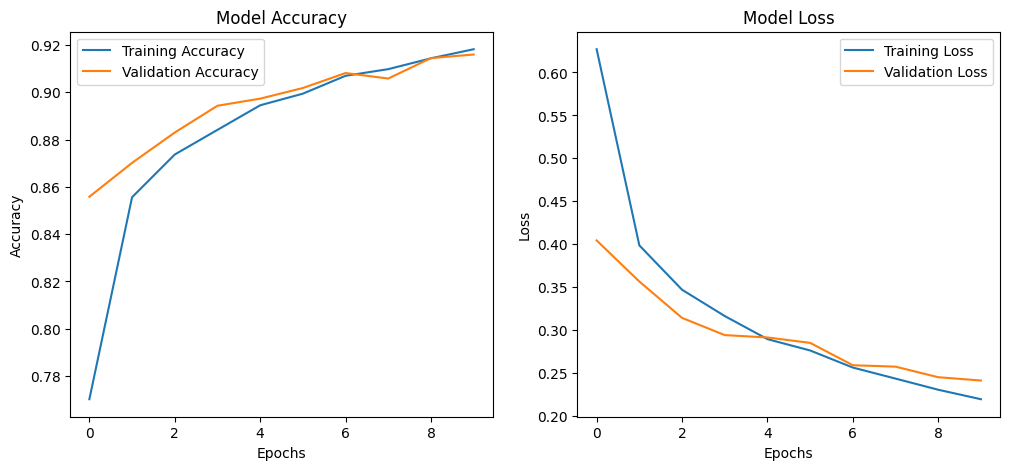

In [51]:
# Plot accuracy and loss
plt.figure(figsize=(12,5))

# Accuracy graph
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

# Loss graph
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step


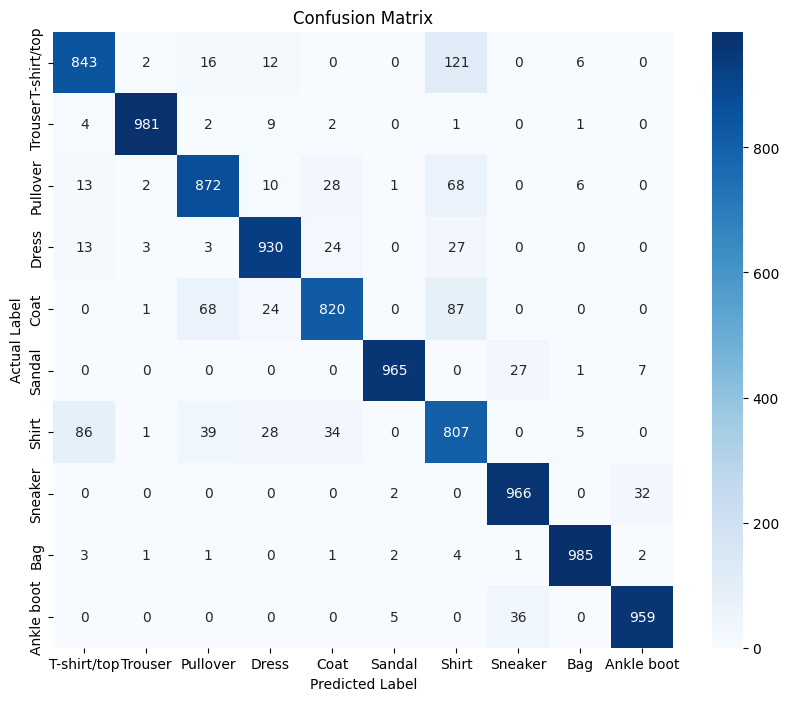

In [52]:
# Confusion matrix
predictions = model.predict(X_test)

predicted_labels = np.argmax(predictions, axis=1)

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

cm = confusion_matrix(y_test, predicted_labels)

plt.figure(figsize=(10,8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

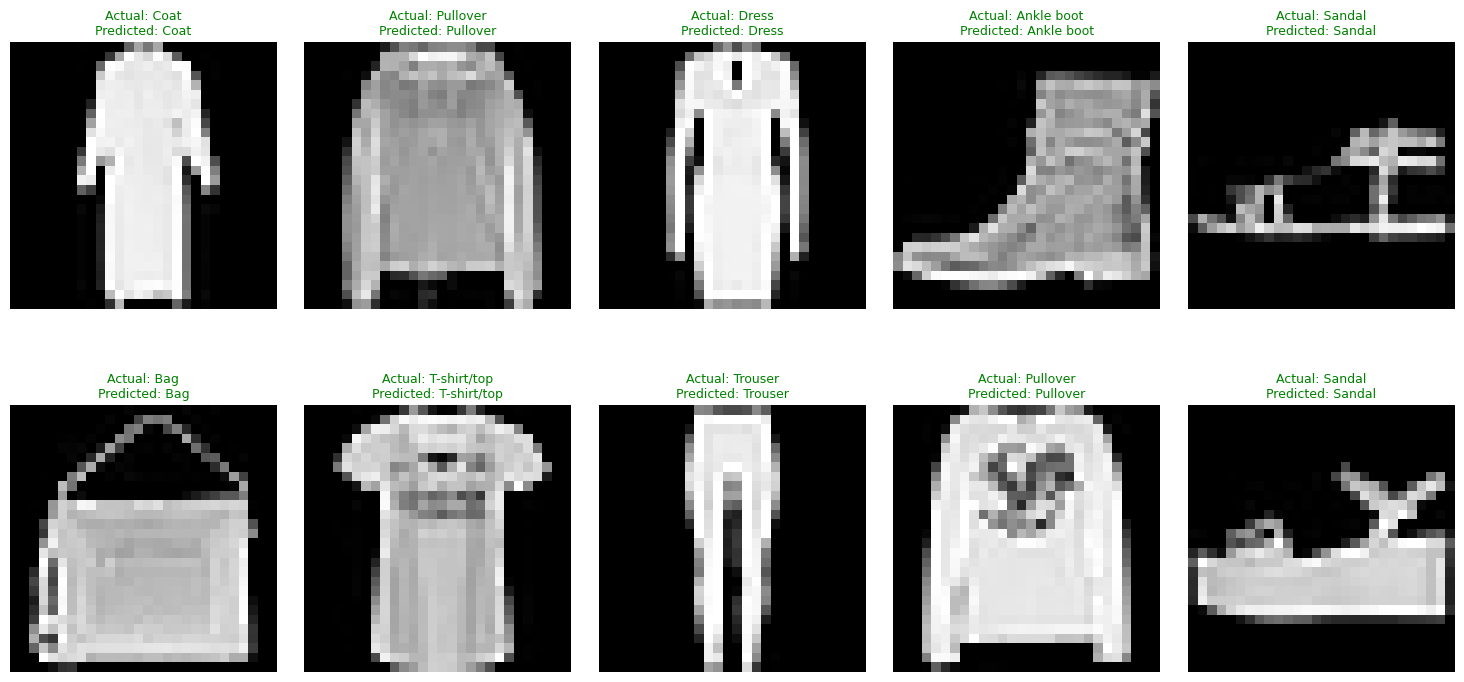

In [57]:
plt.figure(figsize=(15, 8))

for i in range(10):
    n = np.random.randint(0, len(X_test))

    actual = int(y_test[n])
    predicted = int(predicted_labels[n])

    plt.subplot(2, 5, i+1)
    plt.imshow(X_test[n].reshape(28, 28), cmap='gray')

    if(class_names[actual] == class_names[predicted]):
      color = "Green"
    else:
      color = "Red"

    plt.title(f"Actual: {class_names[actual]}\nPredicted: {class_names[predicted]}", color=color, fontsize=9)

    plt.axis('off')

plt.tight_layout(pad=2)
plt.show()

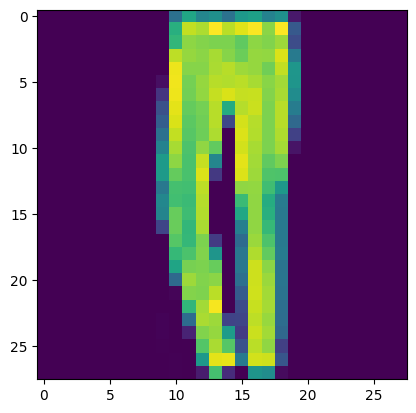

Actual: Trouser
Predicted: Trouser


In [58]:
n = np.random.randint(0, len(X_test))

plt.imshow(X_test[n])
plt.show()

pred = model.predict(X_test[n].reshape(1, 28, 28, 1), verbose=0)

actual = int(y_test[n])
predicted = np.argmax(pred)

print("Actual:", class_names[actual])
print("Predicted:", class_names[predicted])